# sistemas en S

Dominio $s$ (Continuo): Estable si los polos están en el semiplano izquierdo ($\text{Re}(s) < 0$), es decir, a la izquierda del eje imaginario $j\omega$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

## 1. Sistema de 1er Orden: Filtro RC Pasa-Bajas (Clásico)

Un circuito con una resistencia $R$ y un condensador $C$ en serie donde tomamos el voltaje en el condensador.
- Ecuación diferencial: $RC \frac{dv_c(t)}{dt} + v_c(t) = v_{in}(t)$
- Constante de tiempo: $\tau = RC$ (frecuencia de corte $\omega_c = \frac{1}{RC}$)
- Función de transferencia:
$$H(s) = \frac{1}{RCs + 1} = \frac{\omega_c}{s + \omega_c}$$

Tiene un solo polo real negativo en $s = -\frac{1}{RC}$.

In [3]:
# ==========================================
# 1. FILTRO RC PASA-BAJAS (1er Orden)
# ==========================================
R = 1000.0       # 1 kOhm
C = 100e-6       # 100 uF  -> tau = R*C = 0.1 s, wc = 10 rad/s
tau = R * C

num_rc_low = [1.0]
den_rc_low = [tau, 1.0]


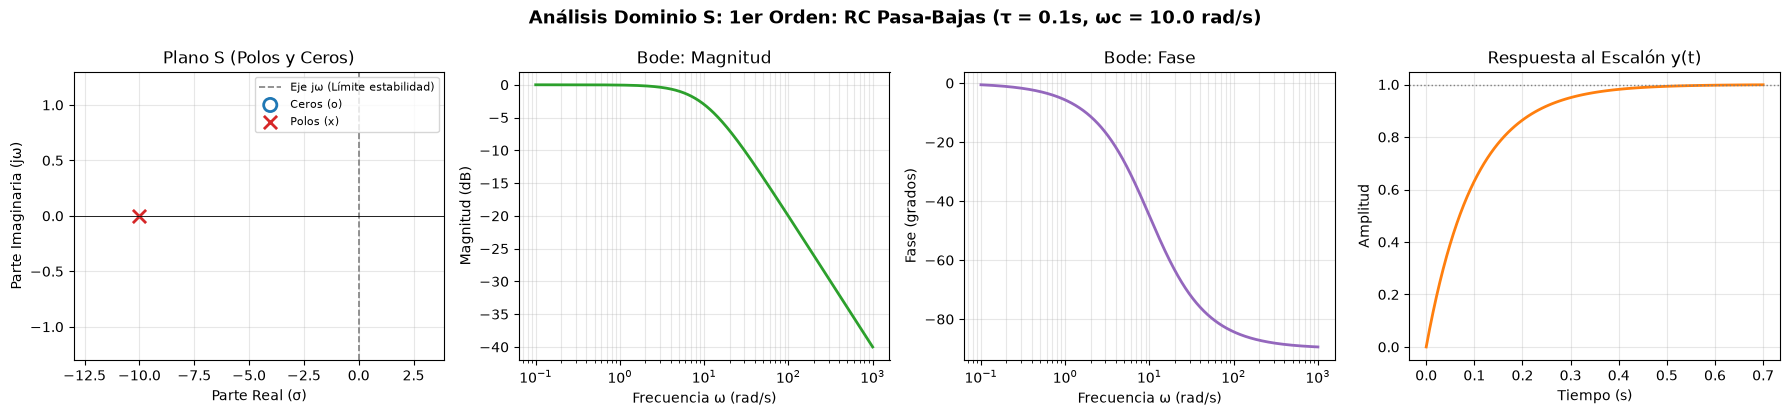

In [4]:
from util_graphs import analizar_sistema_s

analizar_sistema_s(num_rc_low, den_rc_low, f"1er Orden: RC Pasa-Bajas (τ = {tau}s, ωc = {1/tau} rad/s)", w_range=(0.1, 1000))

## 2. Sistema de 1er Orden: Filtro RC Pasa-Altas (Diferenciador con límite)

Si inviertes los componentes y mides el voltaje en la resistencia $R$:

- Función de transferencia:
 $$H(s) = \frac{RCs}{RCs + 1} = \frac{s}{s + \omega_c}$$
 
 
Tiene el mismo polo en $s = -\omega_c$, pero agrega un cero en el origen ($s = 0$), lo que bloquea la corriente continua (DC) y deja pasar las altas frecuencias.

In [6]:
# ==========================================
# 2. FILTRO RC PASA-ALTAS (1er Orden)
# ==========================================
num_rc_high = [tau, 0.0]  # tau*s
den_rc_high = [tau, 1.0]  # tau*s + 1


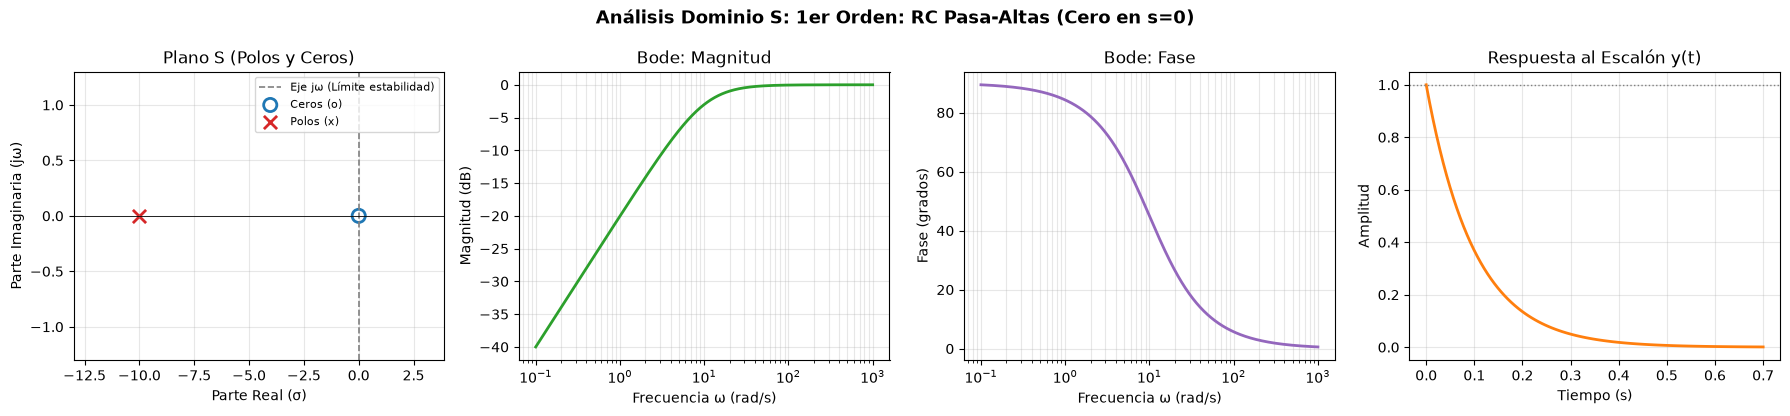

In [7]:
analizar_sistema_s(num_rc_high, den_rc_high, f"1er Orden: RC Pasa-Altas (Cero en s=0)", w_range=(0.1, 1000))

## 3. Sistema de 2do Orden: Circuito RLC Serie / Masa-Resorte-Amortiguador

El estándar de oro en control y electrónica. Se parametriza con su frecuencia natural no amortiguada ($\omega_n$) y su factor de amortiguamiento ($\zeta$, zeta).

- Función de transferencia:$$H(s) = \frac{\omega_n^2}{s^2 + 2\zeta\omega_n s + \omega_n^2}$$

Dependiendo de $\zeta$, sus dos polos se mueven por el plano $s$:
- $\zeta > 1$ (Sobreamortiguado): Dos polos reales distintos en el eje negativo. Lento, sin rebotes.
- $\zeta = 1$ (Críticamente amortiguado): Dos polos reales iguales. Lo más rápido posible sin pasarse.
- $0 < \zeta < 1$ (Subamortiguado): Dos polos complejos conjugados. Oscila antes de estabilizarse (como la suspensión de un auto deportivo).

In [19]:
# ==========================================
# 3. CIRCUITO RLC SUBAMORTIGUADO (2do Orden)
# ==========================================
wn = 20.0        # Frecuencia natural: 20 rad/s
zeta = 0.2       # Poco amortiguamiento -> va a oscilar

num_rlc = [wn**2]
den_rlc = [1.0, 2 * zeta * wn, wn**2]


In [31]:
f = wn/(2*np.pi)

f

3.183098861837907

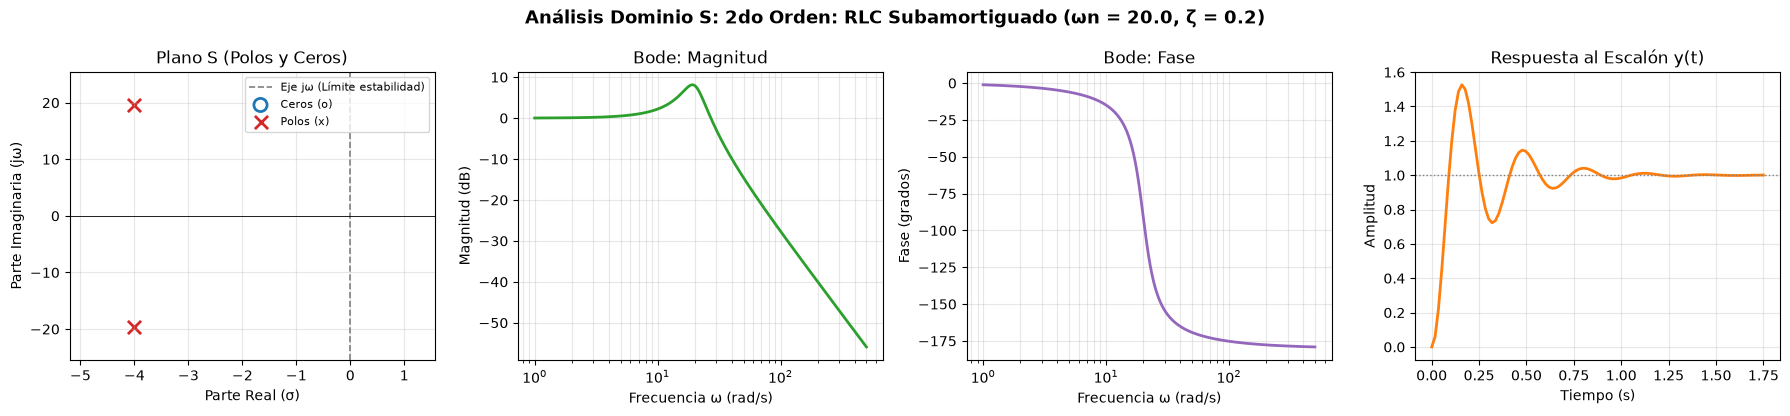

In [20]:
analizar_sistema_s(num_rlc, den_rlc, f"2do Orden: RLC Subamortiguado (ωn = {wn}, ζ = {zeta})", w_range=(1, 500))

## Puente entre ambos mundos ($s \rightarrow z$)

En Tiempo Discreto (Dominio $z$): de $\times\pi\text{ rad/muestra}$ a $\text{Hz}$

En el mundo digital no existe el concepto de "segundos" por sí solo; todo es relativo a la frecuencia de muestreo ($f_s$) con la que capturas la señal (por ejemplo, $f_s = 44100\text{ Hz}$ en audio).

En las gráficas de scipy.signal.freqz, el eje X suele ir de $0$ a $1$ ($\times\pi\text{ rad/muestra}$), donde $1\pi\text{ rad/muestra}$ equivale a la frecuencia de Nyquist ($f_s / 2$).

Si $w_{\text{norm}}$ es el número del eje (entre $0$ y $1$, sin multiplicar por $\pi$):

$$f\text{ (Hz)} = w_{\text{norm}} \cdot \frac{f_s}{2}$$
$$w_{\text{norm}} = \frac{f}{F_s / 2} $$

Si ya tienes el ángulo $\Omega$ en $\text{rad/muestra}$ multiplicado por $\pi$, la fórmula es: $f = \frac{\Omega}{2\pi} \cdot f_s$

In [32]:
Fs= 100.0  # Frecuencia de muestreo: 100 Hz
wnorm = f/(Fs/2)  # Frecuencia normalizada para el diseño digital

wnorm

0.06366197723675814

In [21]:
# Discretizar el filtro RLC con un tiempo de muestreo Ts = 0.01 s
Ts = 0.01
b_d, a_d, _ = signal.cont2discrete((num_rlc, den_rlc), Ts, method='bilinear') # Método de Tustin
print("Numerador discreto b:", b_d.flatten())
print("Denominador discreto a:", a_d.flatten())

Numerador discreto b: [0.00952381 0.01904762 0.00952381]
Denominador discreto a: [ 1.         -1.88571429  0.92380952]


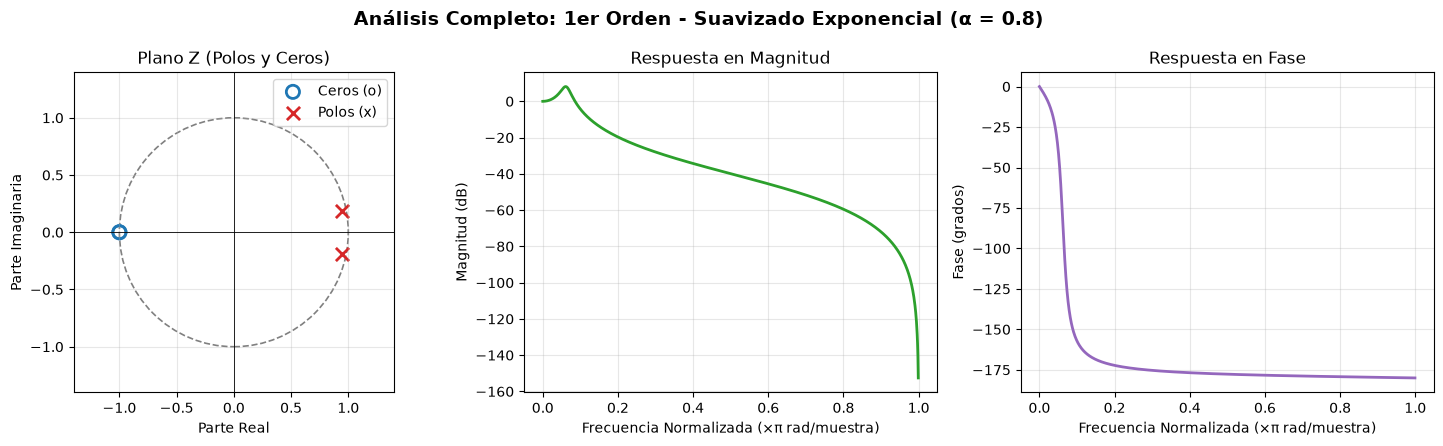

In [22]:
from util_graphs import analizar_sistema

analizar_sistema(b_d.flatten(), a_d.flatten(), "1er Orden - Suavizado Exponencial (α = 0.8)")